# Validation (Role D · Validate)

This notebook is stage 5 of the pipeline. It answers the last two research questions:

- **RQ3** · *Which drugs do patients experience similarly, regardless of official classification?* Every drug gets an **experience profile**, drugs are compared by profile, and the result is checked against the **ATC classes** of D's mapping (for example *N06AB = SSRIs*).
- **RQ4** · *Does the type of experience a patient reports predict their rating?* B8 showed that the mean rating differs between B's clusters (Kruskal-Wallis). Here we test whether cluster membership actually **predicts** a high or low rating, against a baseline and against "only knowing the drug".

## The idea in one paragraph

If the reviews hold real pharmacology, drugs of the same class should *feel* alike to patients: two SSRIs should share more side effects than an SSRI and bupropion. We describe each drug by what its patients report: the share of its reviews that mention each side effect (E's baskets), and the share that falls into each of B's experience clusters. Then we ask whether drugs of the same class are more similar than drugs of different classes, much more than a random relabelling of the classes would give (a permutation test), and we list the exceptions: drugs of different classes that patients describe alike, and drugs of one class that patients describe differently.

## Pipeline overview

| Step | What | Output |
|---|---|---|
| D7 | Load B's clusters, D's ATC classes and E's baskets, one row per review | `reviews` |
| D8 | One identity per drug (active ingredient + ATC class), keep drugs with ≥ 50 reviews | `drug_table.csv` |
| D9 | Experience profiles: side effects (E) and experience types (B) | `drug_profiles_*.csv` |
| D10 | Similarity between drugs and a map of the drugs (hierarchical clustering) | `drug_pair_similarity.csv`, heatmaps |
| D11 | Agreement with ATC classes: permutation test, nearest neighbour, ARI | `atc_agreement.csv` |
| D12 | Exceptions: different class but alike, same class but different | `profile_exceptions.csv` |
| D13 | Rating prediction from the experience type (RQ4) | `rating_prediction.csv` |
| D14 | Save the statistics and print the summary for the report | `role_d_validation_run_stats.json` |

## 0 · Setup and parameters

All the choices are here. The inputs are the outputs of the other roles:

| File | From | Kaggle input | Local folder |
|---|---|---|---|
| `cluster_assignments.parquet` | B (clustering) | B's notebook output | `../clustering/outputs` |
| `scope_review_atc.csv`, `atc_class_names.csv` | D (ATC mapping) | D's notebook output | `../atc-mapping/outputs` |
| `baskets.parquet` | E (frequent itemsets) | E's notebook output | `../frequent_itemsets/outputs` (run E's notebook first) |
| `cluster_labels_final.csv` (optional) | C (NLP) | C's notebook output | `../nlp-embeddings/outputs` |
| `embeddings_masked_v2_all.npy` + `_ids.parquet` (optional) | C (NLP) | C's Kaggle dataset | not in the repo (395 MB) |

The two optional inputs only add rows: without C's embeddings the *meaning* profile is skipped.

In [1]:
import json
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import fcluster, leaves_list, linkage
from scipy.spatial.distance import squareform
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import adjusted_rand_score, balanced_accuracy_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold

pd.set_option('display.max_colwidth', 120)
pd.set_option('display.max_rows', 120)
pd.set_option('display.width', 200)
NOTEBOOK_STARTED = time.perf_counter()

# where the data is read from and written to
INPUT_DIRS = [Path('/kaggle/input'), Path('data'),
              Path('../clustering/outputs'), Path('../atc-mapping/outputs'),
              Path('../frequent_itemsets/outputs'), Path('../nlp-embeddings/outputs')]
OUTPUT_DIR = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('outputs')
FIGURE_DIR = OUTPUT_DIR / 'figures'
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# D7-D8 scope and drugs
CONDITIONS = ['Birth Control', 'Depression', 'Pain', 'Acne']   # the four conditions of the project plan
MIN_REVIEWS_PER_DRUG = 50         # a drug enters the comparison with at least this many reviews in the condition

# D9 profiles
MIN_CONCEPT_REVIEWS = 20          # a side effect enters the profiles if at least this many reviews of the condition report it (E's floor)
DRUG_DOMINATED_SHARE = 0.5        # a B cluster where one drug has >= 50 % of the reviews describes the drug, not an experience
MIN_REVIEWS_LEFT = 20             # a drug needs this many reviews in experience clusters to get an experience-type profile

# D10-D12 agreement with ATC
ATC_LEVELS = {'atc_level_4': 'level 4 (chemical subgroup, e.g. SSRIs)', 'atc_level_3': 'level 3 (pharmacological subgroup, e.g. antidepressants)'}
MAIN_ATC_LEVEL = 'atc_level_4'
N_PERMUTATIONS = 10_000           # random relabellings of the classes in the null model
FDR = 0.05                        # false discovery rate of Benjamini-Hochberg
N_EXCEPTIONS = 5                  # exceptions listed per condition and type
MIN_REVIEWS_FOR_EXCEPTIONS = 100  # exceptions only between drugs with at least this many reviews (profiles of 50 reviews are noisy)

# D13 rating prediction
HIGH_RATING_MIN = 7               # rating >= 7 is a high rating ...
LOW_RATING_MAX = 4                # ... rating <= 4 a low one; 5-6 are left out (see D13)
N_FOLDS = 5
RANDOM_SEED = 42

run_stats = {'parameters': {
    'min_reviews_per_drug': MIN_REVIEWS_PER_DRUG, 'min_concept_reviews': MIN_CONCEPT_REVIEWS,
    'drug_dominated_share': DRUG_DOMINATED_SHARE, 'min_reviews_left': MIN_REVIEWS_LEFT,
    'n_permutations': N_PERMUTATIONS, 'fdr': FDR, 'min_reviews_for_exceptions': MIN_REVIEWS_FOR_EXCEPTIONS,
    'high_rating_min': HIGH_RATING_MIN,
    'low_rating_max': LOW_RATING_MAX, 'n_folds': N_FOLDS, 'random_seed': RANDOM_SEED}}

## D7 · Load and join the outputs of B, D and E

One row per review of the four conditions, with B's k-means cluster, D's ATC class and E's basket of side effects. The three files share `review_id`.

In [2]:
def find_input(file_name, required=True):
    # first match under the input folders: Kaggle inputs, a local data/ folder, or the other roles' outputs
    for folder in INPUT_DIRS:
        if folder.exists():
            matches = sorted(folder.rglob(file_name))
            if matches:
                return matches[0]
    if required:
        raise FileNotFoundError(f'{file_name} not found. On Kaggle: Add Input -> Notebook Output of the role that makes it; '
                                f'locally: run that role\'s notebook first (searched {[str(f) for f in INPUT_DIRS]})')
    return None


clusters = pd.read_parquet(find_input('cluster_assignments.parquet'))          # B
review_atc = pd.read_csv(find_input('scope_review_atc.csv'))                   # D
class_names = pd.read_csv(find_input('atc_class_names.csv')).set_index('atc_class_code')['atc_class_name']
baskets = pd.read_parquet(find_input('baskets.parquet'))                       # E
cluster_labels_path = find_input('cluster_labels_final.csv', required=False)   # C (optional)
for name, path in [('B clusters', 'cluster_assignments.parquet'), ('D classes', 'scope_review_atc.csv'),
                   ('E baskets', 'baskets.parquet'), ('C labels (optional)', 'cluster_labels_final.csv')]:
    print(f'{name:<20} {find_input(path, required=False)}')

reviews = (clusters[['review_id', 'condition_name', 'rating', 'kmeans_cluster']]
           .merge(review_atc[['review_id', 'atc_drug_name', 'generic_name', 'atc_level_4', 'atc_level_3']], on='review_id', how='left')
           .merge(baskets[['review_id', 'basket']], on='review_id', how='left'))
reviews = reviews[reviews['condition_name'].isin(CONDITIONS)]
n_without_class = int(reviews['atc_level_4'].isna().sum())
n_without_basket = int(reviews['basket'].isna().sum())
reviews = reviews.dropna(subset=['atc_level_4', 'basket']).reset_index(drop=True)
reviews['basket'] = reviews['basket'].map(lambda basket: sorted(set(basket)))

run_stats['n_reviews_in_scope'] = int(len(clusters))
run_stats['n_reviews_without_atc_class'] = n_without_class
run_stats['n_reviews_without_basket'] = n_without_basket
run_stats['n_reviews_used'] = int(len(reviews))
print(f'\n{len(clusters):,} reviews from B; {n_without_class} without an ATC class and {n_without_basket} without a basket are left out; '
      f'{len(reviews):,} reviews used')

B clusters           ../clustering/outputs/cluster_assignments.parquet
D classes            ../atc-mapping/outputs/scope_review_atc.csv
E baskets            ../frequent_itemsets/outputs/baskets.parquet
C labels (optional)  ../nlp-embeddings/outputs/cluster_labels_final.csv

36,365 reviews from B; 5 without an ATC class and 0 without a basket are left out; 36,360 reviews used


## D8 · One identity per drug

**Which unit is "a drug"?** Not the drug name: the clean data keeps a review under its brand *or* its generic name (Zoloft or Sertraline), so the same medicine would appear twice and look perfectly similar to itself. Not A's drug family either: a few families join different medicines that shared reviews on Drugs.com (*Gabapentin* also holds Tramadol reviews, *Duloxetine* holds Pregabalin reviews), which would mix two classes in one profile.

We use the **active ingredient** from D's mapping (`generic_name`), so Zoloft and Sertraline are one drug and Gabapentin and Tramadol are two. When one ingredient has two classes in a condition (diclofenac as a gel, M02AA, and as a tablet, M01AB), the class is added to the name, because a gel and a tablet are different experiences. Every drug therefore has exactly one ATC class.

Only drugs with at least 50 reviews in the condition are compared: a profile of a few reviews is mostly noise.

In [3]:
reviews['ingredient'] = reviews['generic_name'].fillna(reviews['atc_drug_name'].str.lower())
n_classes_of_ingredient = reviews.groupby(['condition_name', 'ingredient'])['atc_level_4'].transform('nunique')
reviews['drug'] = np.where(n_classes_of_ingredient > 1,
                           reviews['ingredient'] + ' (' + reviews['atc_level_4'] + ')', reviews['ingredient'])
assert reviews.groupby(['condition_name', 'drug'])['atc_level_4'].nunique().max() == 1, 'every drug should have one class'

drug_table = (reviews.groupby(['condition_name', 'drug'])
              .agg(n_reviews=('review_id', 'size'), atc_level_4=('atc_level_4', 'first'), atc_level_3=('atc_level_3', 'first'),
                   mean_rating=('rating', 'mean'),
                   names_in_reviews=('atc_drug_name', lambda names: ', '.join(names.value_counts().index[:3])))
              .reset_index())
drug_table['class_name'] = drug_table['atc_level_4'].map(class_names)
drug_table['in_comparison'] = drug_table['n_reviews'] >= MIN_REVIEWS_PER_DRUG
drug_table = drug_table.sort_values(['condition_name', 'n_reviews'], ascending=[True, False]).reset_index(drop=True)


def drugs_in(condition):
    # drugs compared in a condition, most reviewed first
    rows = drug_table[(drug_table['condition_name'] == condition) & drug_table['in_comparison']]
    return rows['drug'].tolist()


def class_of(condition, level=MAIN_ATC_LEVEL):
    rows = drug_table[drug_table['condition_name'] == condition]
    return dict(zip(rows['drug'], rows[level]))


scope_rows = []
for condition in CONDITIONS:
    rows = drug_table[drug_table['condition_name'] == condition]
    kept = rows[rows['in_comparison']]
    row = {'condition': condition, 'n_drugs': len(rows), 'n_drugs_compared': len(kept),
           'share_of_reviews_compared': round(kept['n_reviews'].sum() / rows['n_reviews'].sum(), 3)}
    for level in ATC_LEVELS:
        sizes = kept[level].value_counts()
        row[f'n_classes_{level[-1]}'] = int(len(sizes))
        row[f'n_classes_with_2_drugs_{level[-1]}'] = int((sizes >= 2).sum())
        row[f'n_same_class_pairs_{level[-1]}'] = int((sizes * (sizes - 1) // 2).sum())
    scope_rows.append(row)
scope_table = pd.DataFrame(scope_rows).set_index('condition')
run_stats['drugs_compared'] = scope_table.reset_index().to_dict(orient='records')
scope_table

,n_drugs,n_drugs_compared,share_of_reviews_compared,n_classes_4,n_classes_with_2_drugs_4,n_same_class_pairs_4,n_classes_3,n_classes_with_2_drugs_3,n_same_class_pairs_3
condition,,,,,,,,,
Birth Control,20,15,0.997,4,3,40,2,2,69
Depression,53,24,0.944,10,3,56,6,2,139
Pain,75,27,0.906,16,7,17,8,4,101
Acne,34,15,0.960,8,4,11,6,3,25


In [4]:
# the drugs of each condition and their class (check by eye)
for condition in CONDITIONS:
    rows = drug_table[(drug_table['condition_name'] == condition) & drug_table['in_comparison']]
    print(f'\n{condition}: {len(rows)} drugs')
    print(rows[['drug', 'n_reviews', 'atc_level_4', 'class_name', 'mean_rating', 'names_in_reviews']]
          .round(2).to_string(index=False))


Birth Control: 15 drugs
                                           drug  n_reviews atc_level_4                                     class_name  mean_rating                                                         names_in_reviews
                                   etonogestrel       4393       G03AC                                   Progestogens         5.83                                        Nexplanon, Implanon, Etonogestrel
              ethinyl estradiol / norethindrone       3078       G03AA Progestogens and estrogens, fixed combinations         5.65 Ethinyl estradiol / norethindrone, Lo Loestrin Fe, Microgestin Fe 1 / 20
                         levonorgestrel (G02BA)       2871       G02BA                    Intrauterine contraceptives         7.04                                                   Mirena, Skyla, Liletta
             ethinyl estradiol / levonorgestrel       2105       G03AA Progestogens and estrogens, fixed combinations         5.86                 Ethinyl estr

**What the classes allow.** Birth Control is the cleanest test: combined pills (G03AA), progestogen-only methods (G03AC: implant, injection, mini-pill), IUDs (G02BA) and the vaginal ring (G02BB). In Depression, level 4 puts SNRIs, bupropion, mirtazapine and vortioxetine together in *N06AX Other antidepressants*, so a weak result there can come from the class, not from the patients. Pain has many small classes (opioids, NSAIDs, gabapentinoids, antidepressants used for pain), so level 3 (*opioids* vs *other analgesics* vs *anti-inflammatory*) is also reported. Classes with one drug have no same-class pair, but they still count in the different-class pairs.

## D9 · Experience profiles

Two views of "what it is like" to take a drug, both computed from the reviews of one condition:

1. **Side effects (E).** The share of the drug's reviews that report each side effect of E's lexicon (E's baskets, with negations and the treated condition already removed). Side effects reported by fewer than 20 reviews of the condition are left out.
2. **Experience types (B).** The share of the drug's reviews in each of B's k-means clusters. B's clusters are built on TF-IDF, so some of them are just a drug name (*nexplanon*, *mirena*, *pristiq*): such a cluster would make its drug look unique for a trivial reason. A cluster is left out when **one drug has at least 50 % of its reviews**, and the shares are computed over the remaining clusters.

**How two profiles are compared.** Every drug of a condition shares the condition's common experiences (all birth-control methods mention periods and weight), so a raw cosine would call every pair similar. We subtract the mean profile of the condition and take the cosine of what is left (*centred cosine*, like a correlation): two drugs are similar when they **differ from the average drug in the same direction**, for example both above average in weight gain and both below in spotting. Two robustness checks on the side-effect profiles, used only in the agreement table of D11:

- **z-scored**: every side effect scaled to unit variance across the drugs, so that rare side effects (hair loss) weigh as much as common ones (weight gain);
- **composition**: every drug's profile divided by its total, so it says *which* side effects patients report and not *how many*. Without it, two well-tolerated drugs can look alike only because both are below average on everything.

In [5]:
def side_effect_profile(condition):
    # % of each drug's reviews that report each side effect
    sub = reviews[reviews['condition_name'] == condition]
    concept_counts = Counter(concept for basket in sub['basket'] for concept in basket)
    concepts = sorted(concept for concept, n in concept_counts.items() if n >= MIN_CONCEPT_REVIEWS)
    flags = pd.DataFrame([[concept in set(basket) for concept in concepts] for basket in sub['basket']],
                         columns=concepts, index=sub.index)
    profile = flags.groupby(sub['drug']).mean() * 100
    return profile.loc[drugs_in(condition)]


def experience_type_profile(condition):
    # % of each drug's reviews in each of B's clusters, without the clusters that are one drug
    sub = reviews[reviews['condition_name'] == condition]
    top_drug_share = sub.groupby('kmeans_cluster')['drug'].agg(lambda drugs: drugs.value_counts(normalize=True).iloc[0])
    drug_clusters = top_drug_share[top_drug_share >= DRUG_DOMINATED_SHARE].index
    kept = sub[~sub['kmeans_cluster'].isin(drug_clusters)]
    reviews_left = kept['drug'].value_counts()
    drugs = [drug for drug in drugs_in(condition) if reviews_left.get(drug, 0) >= MIN_REVIEWS_LEFT]
    profile = pd.crosstab(kept['drug'], kept['kmeans_cluster'], normalize='index').loc[drugs] * 100
    info = {'n_clusters': int(sub['kmeans_cluster'].nunique()), 'n_drug_clusters_left_out': int(len(drug_clusters)),
            'share_of_reviews_left_out': round(1 - len(kept) / len(sub), 3),
            'drugs_without_profile': [drug for drug in drugs_in(condition) if drug not in drugs]}
    return profile, info


def zscored(profile):
    # every side effect scaled to unit variance across the drugs (robustness check)
    spread = profile.std(ddof=0)
    return (profile.loc[:, spread > 0] - profile.mean()) / spread[spread > 0]


def composition(profile):
    # which side effects, not how many: each drug's profile divided by its total (robustness check)
    total = profile.sum(axis=1)
    return profile.div(total.where(total > 0, 1), axis=0) * 100


profiles, profile_info = {}, {}
for condition in CONDITIONS:
    profiles[(condition, 'side effects')] = side_effect_profile(condition)
    profiles[(condition, 'side effects (z-scored)')] = zscored(profiles[(condition, 'side effects')])
    profiles[(condition, 'side effects (composition)')] = composition(profiles[(condition, 'side effects')])
    profiles[(condition, 'experience types')], profile_info[condition] = experience_type_profile(condition)

profile_rows = []
for (condition, view), profile in profiles.items():
    profile_rows.append({'condition': condition, 'view': view, 'n_drugs': profile.shape[0], 'n_dimensions': profile.shape[1]})
print(pd.DataFrame(profile_rows).to_string(index=False))
print('\nexperience types: B clusters left out because one drug has >= '
      f'{DRUG_DOMINATED_SHARE:.0%} of their reviews')
print(pd.DataFrame(profile_info).T.to_string())
run_stats['experience_type_clusters_left_out'] = profile_info

    condition                       view  n_drugs  n_dimensions
Birth Control               side effects       15            50
Birth Control    side effects (z-scored)       15            50
Birth Control side effects (composition)       15            50
Birth Control           experience types       15            11
   Depression               side effects       24            40
   Depression    side effects (z-scored)       24            40
   Depression side effects (composition)       24            40
   Depression           experience types       24            20
         Pain               side effects       27            29
         Pain    side effects (z-scored)       27            29
         Pain side effects (composition)       27            29
         Pain           experience types       27            21
         Acne               side effects       15            28
         Acne    side effects (z-scored)       15            28
         Acne side effects (composition)

### Optional third view: meaning (C's Sentence-BERT embeddings, drug names masked)

If C's masked embeddings are an input (Kaggle dataset of the NLP lead), each drug also gets the **mean embedding of its reviews**: the average meaning of what its patients write, with drug names replaced by *medication* so that the name itself cannot make two drugs alike. The same centred cosine is used. Without the embeddings this view is skipped and every later step runs on the two views above.

In [6]:
embedding_path = find_input('embeddings_masked_v2_all.npy', required=False)
embedding_ids_path = find_input('embeddings_masked_v2_all_ids.parquet', required=False)
if embedding_path is not None and embedding_ids_path is not None:
    embeddings = np.load(embedding_path, mmap_mode='r')
    embedding_ids = pd.read_parquet(embedding_ids_path)['review_id'].to_numpy()
    row_of_review = pd.Series(np.arange(len(embedding_ids)), index=embedding_ids)
    for condition in CONDITIONS:
        sub = reviews[(reviews['condition_name'] == condition) & reviews['review_id'].isin(row_of_review.index)]
        vectors = np.asarray(embeddings[row_of_review.loc[sub['review_id']].to_numpy()], dtype=np.float64)
        mean_vectors = pd.DataFrame(vectors, index=sub['drug'].to_numpy()).groupby(level=0).mean()
        profiles[(condition, 'meaning (masked)')] = mean_vectors.loc[[d for d in drugs_in(condition) if d in mean_vectors.index]]
    print(f'meaning view added from {embedding_path} ({len(embedding_ids):,} reviews)')
    run_stats['meaning_view'] = True
else:
    print('C\'s masked embeddings are not an input: the meaning view is skipped')
    run_stats['meaning_view'] = False

VIEWS = list(dict.fromkeys(view for _, view in profiles))
print('views:', VIEWS)

C's masked embeddings are not an input: the meaning view is skipped
views: ['side effects', 'side effects (z-scored)', 'side effects (composition)', 'experience types']


## D10 · Similarity between drugs and a map of the drugs

The centred cosine of every pair of drugs, per condition and view. The heatmaps order the drugs by **hierarchical clustering** (average linkage on 1 − similarity, the course's agglomerative clustering applied to drugs instead of reviews); the colour of each drug name is its ATC class. If classes matter to patients, drugs of one colour should sit next to each other.

In [7]:
def centred_cosine(profile):
    X = profile.to_numpy(dtype=float)
    X = X - X.mean(axis=0)
    norms = np.linalg.norm(X, axis=1, keepdims=True)
    X = X / np.where(norms == 0, 1, norms)
    return pd.DataFrame(X @ X.T, index=profile.index, columns=profile.index)


def drug_tree(similarity):
    # average-linkage hierarchical clustering on the distance 1 - similarity
    distance = (1 - similarity.to_numpy()).clip(min=0)
    np.fill_diagonal(distance, 0)
    return linkage(squareform(distance, checks=False), method='average')


similarities = {key: centred_cosine(profile) for key, profile in profiles.items()}
trees = {key: drug_tree(similarity) for key, similarity in similarities.items()}

pair_rows = []
for (condition, view), similarity in similarities.items():
    class_4, class_3 = class_of(condition, 'atc_level_4'), class_of(condition, 'atc_level_3')
    drugs = similarity.index.tolist()
    for i in range(len(drugs)):
        for j in range(i + 1, len(drugs)):
            a, b = drugs[i], drugs[j]
            pair_rows.append({'condition': condition, 'view': view, 'drug_a': a, 'drug_b': b,
                              'similarity': similarity.iat[i, j], 'class_a': class_4[a], 'class_b': class_4[b],
                              'same_class_level_4': class_4[a] == class_4[b], 'same_class_level_3': class_3[a] == class_3[b]})
pairs = pd.DataFrame(pair_rows)
print(pairs.groupby(['condition', 'view']).size().unstack())

view           experience types  side effects  side effects (composition)  side effects (z-scored)
condition                                                                                         
Acne                        105           105                         105                      105
Birth Control               105           105                         105                      105
Depression                  276           276                         276                      276
Pain                        351           351                         351                      351


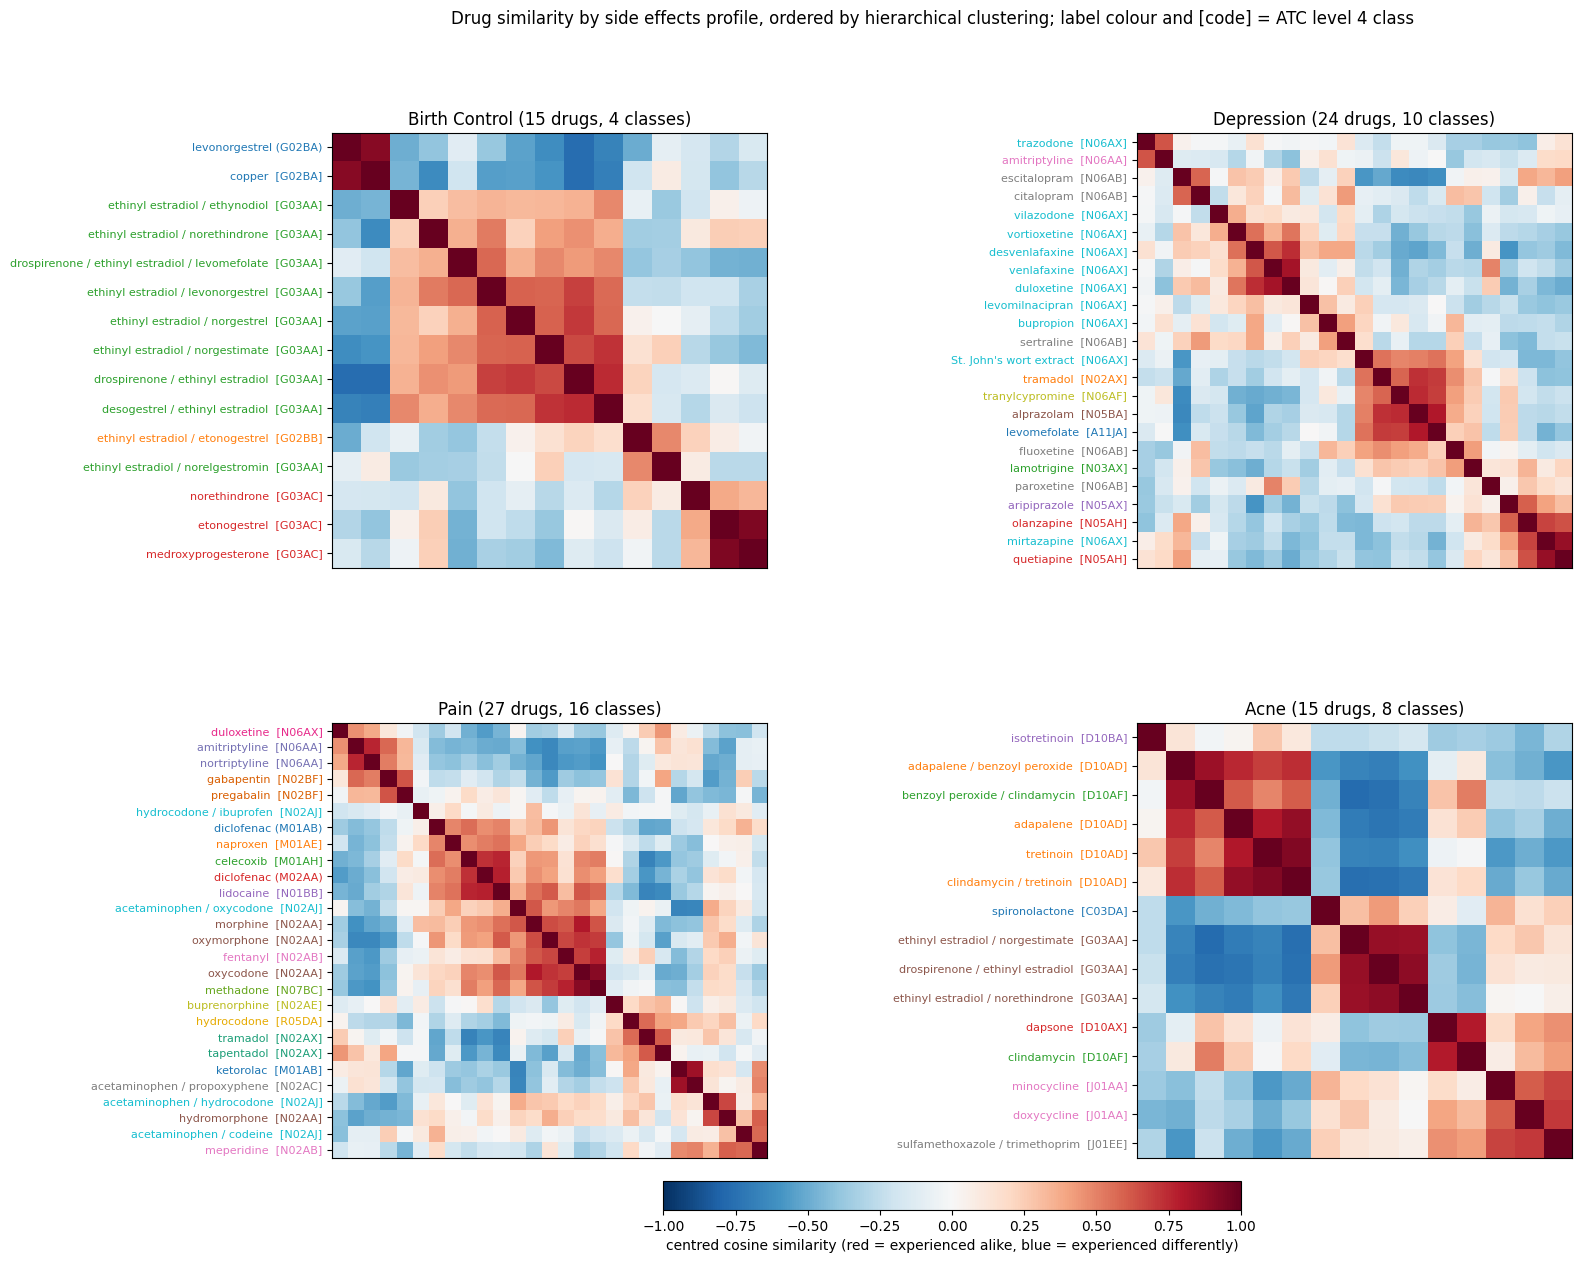

In [8]:
CLASS_COLOURS = list(plt.get_cmap('tab10').colors) + list(plt.get_cmap('Dark2').colors)


def plot_heatmaps(view, file_name):
    # one panel per condition; the matrix is symmetric, so only the rows are labelled (drug [ATC level 4 class])
    fig, axes = plt.subplots(2, 2, figsize=(16, 15), gridspec_kw={'wspace': 0.85, 'hspace': 0.15})
    for ax, condition in zip(axes.ravel(), CONDITIONS):
        if (condition, view) not in similarities:
            ax.axis('off')
            continue
        similarity = similarities[(condition, view)]
        order = similarity.index[leaves_list(trees[(condition, view)])]
        classes = class_of(condition)
        class_colour = {c: CLASS_COLOURS[k % len(CLASS_COLOURS)] for k, c in enumerate(sorted({classes[d] for d in order}))}
        image = ax.imshow(similarity.loc[order, order].to_numpy(), cmap='RdBu_r', vmin=-1, vmax=1)
        ax.set_xticks([])
        ax.set_yticks(range(len(order)))
        ax.set_yticklabels([drug if drug.endswith(f'({classes[drug]})') else f'{drug}  [{classes[drug]}]' for drug in order],
                           fontsize=8)
        for label, drug in zip(ax.get_yticklabels(), order):
            label.set_color(class_colour[classes[drug]])
        ax.set_title(f'{condition} ({len(order)} drugs, {len(class_colour)} classes)')
    fig.colorbar(image, ax=axes, orientation='horizontal', fraction=0.025, pad=0.02,
                 label='centred cosine similarity (red = experienced alike, blue = experienced differently)')
    fig.suptitle(f'Drug similarity by {view} profile, ordered by hierarchical clustering; label colour and [code] = ATC level 4 class',
                 y=0.91)
    fig.savefig(FIGURE_DIR / file_name, dpi=130, bbox_inches='tight')
    plt.show()


plot_heatmaps('side effects', 'drug_similarity_side_effects.png')

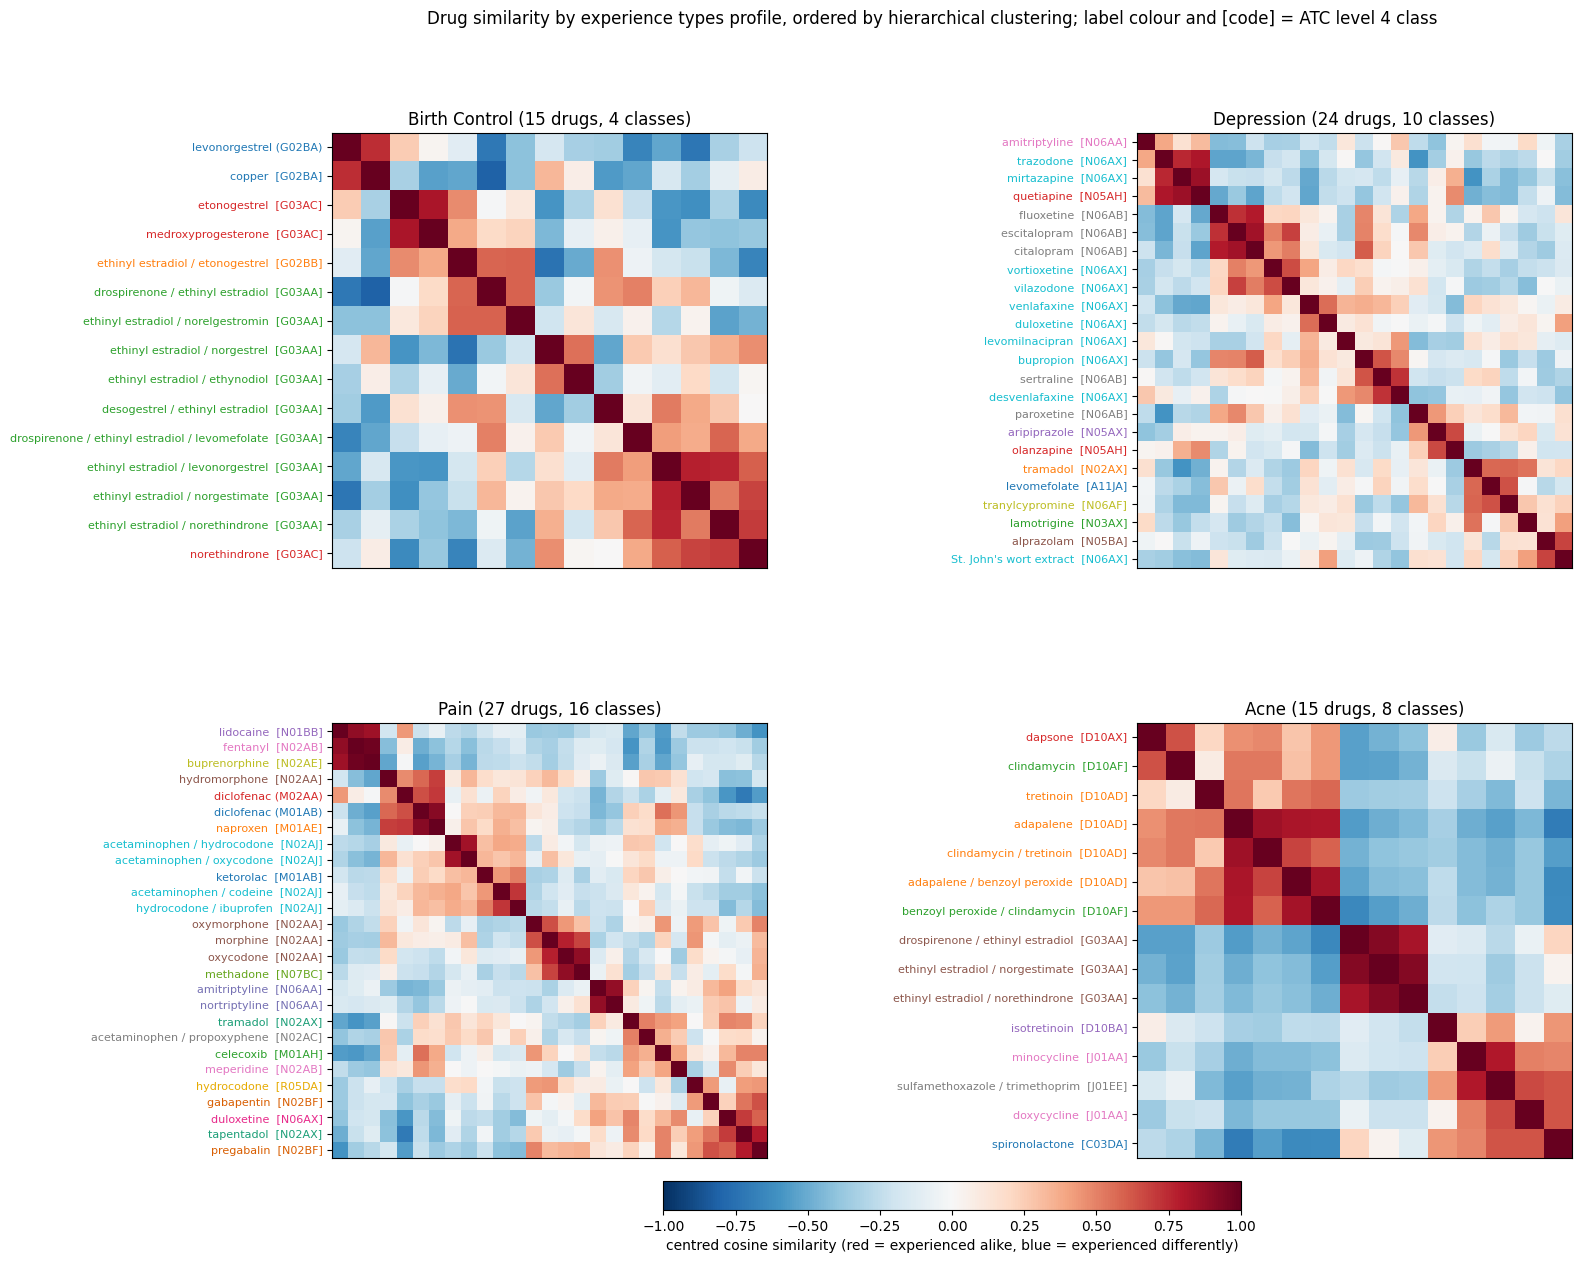

In [9]:
plot_heatmaps('experience types', 'drug_similarity_experience_types.png')

## D11 · Do drugs of the same ATC class feel alike?

Three measures per condition, view and ATC level, each with the same **null model**: the class labels are shuffled among the drugs 10,000 times (keeping the number of drugs per class), which shows what the measure looks like when the classes mean nothing.

1. **Same-class gap** (main test): mean similarity of same-class pairs minus mean similarity of different-class pairs. A positive gap that few shuffles reach means classes and experiences agree. The p-value is one-sided and the q-value corrects for the number of tests (Benjamini-Hochberg).
2. **Nearest neighbour**: for each drug whose class has another drug in the comparison, is its most similar drug in the same class? Compared with the share the shuffles give.
3. **Adjusted Rand index (ARI)** between the groups of the drug tree (cut into as many groups as there are classes) and the classes: 0 = chance, 1 = the tree finds the classes exactly.

In [10]:
def same_class_gap(S, labels, iu):
    same = (labels[:, None] == labels[None, :])[iu]
    values = S[iu]
    return values[same].mean() - values[~same].mean()


def nearest_neighbour_agreement(S, labels, eligible):
    S = S.copy()
    np.fill_diagonal(S, -np.inf)
    nearest = S.argmax(axis=1)
    return (labels[nearest] == labels)[eligible].mean()


def bh_qvalues(p_values):
    p = np.asarray(p_values, dtype=float)
    q = np.full_like(p, np.nan)
    ok = ~np.isnan(p)
    order = np.argsort(p[ok])
    ranked = p[ok][order] * ok.sum() / np.arange(1, ok.sum() + 1)
    ranked = np.minimum.accumulate(ranked[::-1])[::-1].clip(max=1)
    q_ok = np.empty_like(ranked)
    q_ok[order] = ranked
    q[ok] = q_ok
    return q


permutation_rng = np.random.default_rng(RANDOM_SEED)
agreement_rows, null_gaps = [], {}
for (condition, view), similarity in similarities.items():
    S = similarity.to_numpy()
    iu = np.triu_indices(len(S), k=1)
    for level in ATC_LEVELS:
        labels = np.array([class_of(condition, level)[drug] for drug in similarity.index])
        class_sizes = pd.Series(labels).value_counts()
        eligible = np.array([class_sizes[label] >= 2 for label in labels])
        n_same_pairs = int((class_sizes * (class_sizes - 1) // 2).sum())
        row = {'condition': condition, 'view': view, 'atc_level': level, 'n_drugs': len(labels),
               'n_classes': int(len(class_sizes)), 'n_same_class_pairs': n_same_pairs}
        if n_same_pairs == 0 or n_same_pairs == len(iu[0]):
            agreement_rows.append(row)
            continue
        groups = fcluster(trees[(condition, view)], t=len(class_sizes), criterion='maxclust')
        observed = (same_class_gap(S, labels, iu), nearest_neighbour_agreement(S, labels, eligible),
                    adjusted_rand_score(labels, groups))
        null = np.empty((N_PERMUTATIONS, 3))
        for k in range(N_PERMUTATIONS):
            shuffled = permutation_rng.permutation(labels)
            shuffled_eligible = np.array([class_sizes[label] >= 2 for label in shuffled])
            null[k] = (same_class_gap(S, shuffled, iu), nearest_neighbour_agreement(S, shuffled, shuffled_eligible),
                       adjusted_rand_score(shuffled, groups))
        p_values = [(1 + (null[:, m] >= observed[m]).sum()) / (1 + N_PERMUTATIONS) for m in range(3)]
        same = (labels[:, None] == labels[None, :])[iu]
        row.update({'mean_similarity_same_class': S[iu][same].mean(), 'mean_similarity_other_class': S[iu][~same].mean(),
                    'same_class_gap': observed[0], 'p_gap': p_values[0],
                    'nearest_neighbour_same_class': observed[1], 'nearest_neighbour_chance': null[:, 1].mean(), 'p_nearest': p_values[1],
                    'ari_tree_vs_class': observed[2], 'p_ari': p_values[2]})
        null_gaps[(condition, view, level)] = null[:, 0]
        agreement_rows.append(row)

agreement = pd.DataFrame(agreement_rows)
agreement['q_gap'] = bh_qvalues(agreement['p_gap'])
agreement['significant'] = agreement['q_gap'] < FDR
agreement_main = agreement[agreement['atc_level'] == MAIN_ATC_LEVEL]
print('ATC level 4')
print(agreement_main.drop(columns='atc_level').round(3).to_string(index=False))
print('\nATC level 3')
print(agreement[agreement['atc_level'] == 'atc_level_3'].drop(columns='atc_level').round(3).to_string(index=False))

ATC level 4
    condition                       view  n_drugs  n_classes  n_same_class_pairs  mean_similarity_same_class  mean_similarity_other_class  same_class_gap  p_gap  nearest_neighbour_same_class  nearest_neighbour_chance  p_nearest  ari_tree_vs_class  p_ari  q_gap  significant
Birth Control               side effects       15          4                  40                       0.365                       -0.232           0.597  0.000                         0.929                     0.409      0.000              0.812  0.000  0.000         True
Birth Control    side effects (z-scored)       15          4                  40                       0.044                       -0.128           0.172  0.001                         0.857                     0.408      0.001              0.296  0.019  0.002         True
Birth Control side effects (composition)       15          4                  40                       0.407                       -0.183           0.590  0.000      

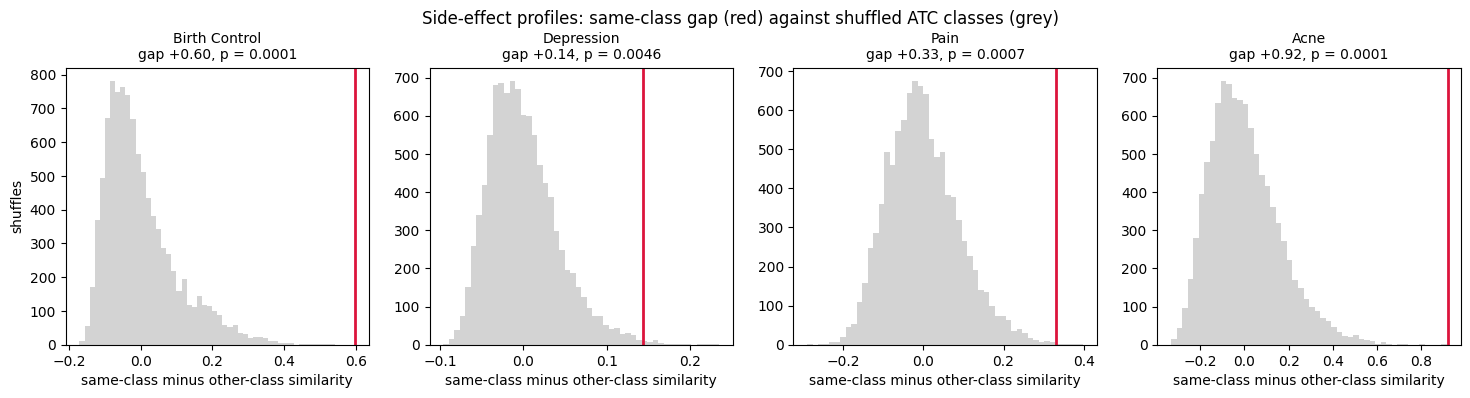

In [11]:
# the main test, side-effect profiles and ATC level 4: observed gap against the 10,000 shuffles
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, condition in zip(axes, CONDITIONS):
    key = (condition, 'side effects', MAIN_ATC_LEVEL)
    if key not in null_gaps:
        ax.axis('off')
        continue
    row = agreement[(agreement['condition'] == condition) & (agreement['view'] == 'side effects')
                    & (agreement['atc_level'] == MAIN_ATC_LEVEL)].iloc[0]
    ax.hist(null_gaps[key], bins=50, color='lightgrey')
    ax.axvline(row['same_class_gap'], color='crimson', lw=2)
    ax.set_title(f'{condition}\ngap {row["same_class_gap"]:+.2f}, p = {row["p_gap"]:.4f}', fontsize=10)
    ax.set_xlabel('same-class minus other-class similarity')
axes[0].set_ylabel('shuffles')
fig.suptitle('Side-effect profiles: same-class gap (red) against shuffled ATC classes (grey)', y=1.04)
fig.savefig(FIGURE_DIR / 'atc_permutation_test.png', dpi=130, bbox_inches='tight')
plt.show()

## D12 · Exceptions: where patients and the classification disagree

The interesting cases for the report. Per condition, on the side-effect profiles (the view that can be explained in words), among drugs with at least 100 reviews (with 50 reviews a profile is too noisy to single out one pair):

- **different class, experienced alike**: the most similar pairs of drugs from different ATC classes;
- **same class, experienced differently**: the least similar pairs of drugs from the same class.

For each pair, `why` lists the side effects that drive the similarity: for an alike pair, the effects where both drugs are above (or both below) the condition average; for a different pair, the effects where one is above and the other below. The numbers are percentage points away from the condition average (*weight gain +9/+7* = 9 and 7 points more reviews mention weight gain than for the average drug).

In [12]:
def why(condition, a, b, alike, k=3):
    profile = profiles[(condition, 'side effects')]
    deviation = profile - profile.mean()
    contribution = (deviation.loc[a] * deviation.loc[b]).sort_values(ascending=not alike).head(k)
    return '; '.join(f'{concept} {deviation.at[a, concept]:+.0f}/{deviation.at[b, concept]:+.0f}' for concept in contribution.index)


n_reviews_of = drug_table.set_index(['condition_name', 'drug'])['n_reviews']
exception_rows = []
for condition in CONDITIONS:
    condition_pairs = pairs[(pairs['condition'] == condition) & (pairs['view'] == 'side effects')]
    big_enough = [n_reviews_of[(condition, drug)] >= MIN_REVIEWS_FOR_EXCEPTIONS for drug in condition_pairs['drug_a']]
    big_enough &= np.array([n_reviews_of[(condition, drug)] >= MIN_REVIEWS_FOR_EXCEPTIONS for drug in condition_pairs['drug_b']])
    condition_pairs = condition_pairs[big_enough]
    alike = condition_pairs[~condition_pairs['same_class_level_4']].nlargest(N_EXCEPTIONS, 'similarity')
    different = condition_pairs[condition_pairs['same_class_level_4']].nsmallest(N_EXCEPTIONS, 'similarity')
    for kind, rows, is_alike in [('different class, alike', alike, True), ('same class, different', different, False)]:
        for pair in rows.itertuples():
            exception_rows.append({'condition': condition, 'kind': kind, 'drug_a': pair.drug_a, 'drug_b': pair.drug_b,
                                   'class_a': pair.class_a, 'class_b': pair.class_b, 'similarity': round(pair.similarity, 3),
                                   'why': why(condition, pair.drug_a, pair.drug_b, is_alike)})
exceptions = pd.DataFrame(exception_rows)
for (condition, kind), rows in exceptions.groupby(['condition', 'kind'], sort=False):
    print(f'\n{condition} · {kind}')
    print(rows.drop(columns=['condition', 'kind']).to_string(index=False))


Birth Control · different class, alike
                           drug_a                             drug_b class_a class_b  similarity                                                  why
 ethinyl estradiol / etonogestrel ethinyl estradiol / norelgestromin   G02BB   G03AA       0.479  acne_breakout -8/-10; cramps -11/-5; spotting -9/-6
                     etonogestrel  ethinyl estradiol / norethindrone   G03AC   G03AA       0.245      no_period +13/+3; cramps -13/-2; spotting +5/+3
ethinyl estradiol / norethindrone                medroxyprogesterone   G03AA   G03AC       0.236 no_period +3/+19; weight_gain +1/+14; spotting +3/+7
 ethinyl estradiol / etonogestrel                      norethindrone   G02BB   G03AC       0.234     cramps -11/-9; acne_breakout -8/-2; nausea -2/-5
 ethinyl estradiol / etonogestrel   drospirenone / ethinyl estradiol   G02BB   G03AA       0.222       cramps -11/-9; spotting -9/-4; no_period -4/-4

Birth Control · same class, different
                     

## D13 · Does the type of experience predict the rating? (RQ4)

B8 showed that the mean rating differs between B's clusters. A difference in means is not yet a prediction: here a model sees only *which experience cluster a review falls in* and has to say whether the rating is high (≥ 7) or low (≤ 4).

- **Why two classes and not 1-10.** Ratings are polarised (many 10s and 1s, few in between, see the table below), so the useful question is high vs low; the reviews rated 5-6 are left out.
- **Model.** Logistic regression with balanced class weights, 5-fold stratified cross-validation, per condition. Scores: ROC AUC (0.5 = guessing, 1 = perfect ranking) and balanced accuracy (0.5 = guessing).
- **What it is compared with.** The drug alone (one indicator per drug): does knowing the *experience* say more than knowing the *medicine*? E's side effects alone, the drug plus the experience type, and all three together.

B's clusters were built from the text without the rating, so using them as features is not a leak; they were fitted on all reviews of the condition, which is how they would be used on a new review.

In [13]:
polarisation = (reviews.groupby('condition_name')['rating']
                .agg(share_1_or_10=lambda r: r.isin([1, 10]).mean(), share_5_or_6=lambda r: r.isin([5, 6]).mean(),
                     share_high=lambda r: (r >= HIGH_RATING_MIN).mean(), share_low=lambda r: (r <= LOW_RATING_MAX).mean())
                .reindex(CONDITIONS).round(3))
run_stats['rating_polarisation'] = polarisation.to_dict(orient='index')
polarisation

,share_1_or_10,share_5_or_6,share_high,share_low
condition_name,,,,
Birth Control,0.353,0.126,0.524,0.351
Depression,0.395,0.091,0.691,0.218
Pain,0.437,0.062,0.762,0.176
Acne,0.406,0.087,0.713,0.200


In [14]:
FEATURE_SETS = {
    'drug only': ['drug'],
    'experience type (B clusters)': ['cluster'],
    'side effects (E baskets)': ['side_effects'],
    'drug + experience type': ['drug', 'cluster'],
    'drug + experience type + side effects': ['drug', 'cluster', 'side_effects'],
}
if run_stats['meaning_view']:
    FEATURE_SETS['meaning (C embeddings, masked)'] = ['embedding']


def feature_matrix(sub, blocks):
    parts = []
    if 'drug' in blocks:
        parts.append(pd.get_dummies(sub['drug'], prefix='drug').to_numpy(dtype=float))
    if 'cluster' in blocks:
        parts.append(pd.get_dummies(sub['kmeans_cluster'], prefix='cluster').to_numpy(dtype=float))
    if 'side_effects' in blocks:
        concepts = sorted({concept for basket in sub['basket'] for concept in basket})
        flags = np.array([[concept in set(basket) for concept in concepts] for basket in sub['basket']], dtype=float)
        parts.append(np.column_stack([flags, flags.sum(axis=1)]))
    if 'embedding' in blocks:
        parts.append(np.asarray(embeddings[row_of_review.loc[sub['review_id']].to_numpy()], dtype=float))
    return np.hstack(parts)


prediction_rows = []
folds = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_SEED)
for condition in CONDITIONS:
    sub = reviews[(reviews['condition_name'] == condition)
                  & ((reviews['rating'] >= HIGH_RATING_MIN) | (reviews['rating'] <= LOW_RATING_MAX))].reset_index(drop=True)
    if 'embedding' in sum(FEATURE_SETS.values(), []):
        sub = sub[sub['review_id'].isin(row_of_review.index)].reset_index(drop=True)
    y = (sub['rating'] >= HIGH_RATING_MIN).to_numpy(dtype=int)
    prediction_rows.append({'condition': condition, 'features': 'baseline (always the majority)', 'n_reviews': len(y),
                            'share_high': y.mean(), 'auc_mean': 0.5, 'auc_sd': 0.0, 'balanced_accuracy_mean': 0.5,
                            'balanced_accuracy_sd': 0.0})
    for name, blocks in FEATURE_SETS.items():
        X = feature_matrix(sub, blocks)
        aucs, accuracies = [], []
        for train, test in folds.split(X, y):
            model = LogisticRegression(max_iter=3000, class_weight='balanced')
            model.fit(X[train], y[train])
            aucs.append(roc_auc_score(y[test], model.predict_proba(X[test])[:, 1]))
            accuracies.append(balanced_accuracy_score(y[test], model.predict(X[test])))
        prediction_rows.append({'condition': condition, 'features': name, 'n_reviews': len(y), 'share_high': y.mean(),
                                'n_features': X.shape[1], 'auc_mean': np.mean(aucs), 'auc_sd': np.std(aucs),
                                'balanced_accuracy_mean': np.mean(accuracies), 'balanced_accuracy_sd': np.std(accuracies)})
prediction = pd.DataFrame(prediction_rows)
prediction.pivot(index='features', columns='condition', values='auc_mean').reindex(
    ['baseline (always the majority)'] + list(FEATURE_SETS))[CONDITIONS].round(3)

condition,Birth Control,Depression,Pain,Acne
features,,,,
baseline (always the majority),0.500,0.500,0.500,0.500
drug only,0.580,0.620,0.705,0.661
experience type (B clusters),0.687,0.655,0.672,0.680
side effects (E baskets),0.756,0.669,0.606,0.664
drug + experience type,0.691,0.694,0.744,0.707
drug + experience type + side effects,0.789,0.737,0.770,0.735


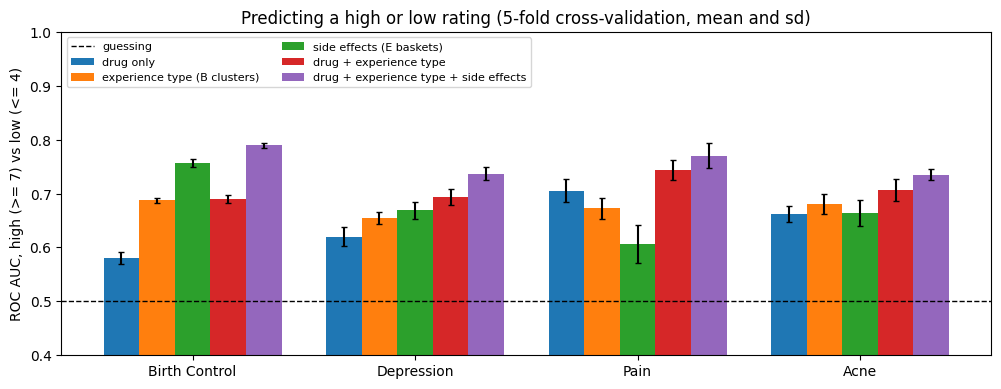

In [15]:
fig, ax = plt.subplots(figsize=(12, 4.2))
names = list(FEATURE_SETS)
width = 0.8 / len(names)
x = np.arange(len(CONDITIONS))
for k, name in enumerate(names):
    rows = prediction[prediction['features'] == name].set_index('condition').reindex(CONDITIONS)
    ax.bar(x + k * width - 0.4 + width / 2, rows['auc_mean'], width, yerr=rows['auc_sd'], label=name, capsize=2)
ax.axhline(0.5, color='black', lw=1, ls='--', label='guessing')
ax.set_xticks(x)
ax.set_xticklabels(CONDITIONS)
ax.set_ylim(0.4, 1)
ax.set_ylabel(f'ROC AUC, high (>= {HIGH_RATING_MIN}) vs low (<= {LOW_RATING_MAX})')
ax.legend(fontsize=8, ncol=2, loc='upper left')
ax.set_title(f'Predicting a high or low rating ({N_FOLDS}-fold cross-validation, mean and sd)')
fig.savefig(FIGURE_DIR / 'rating_prediction_auc.png', dpi=130, bbox_inches='tight')
plt.show()

### Which experiences go with high and low ratings

The three clusters with the highest and the three with the lowest mean rating in each condition, with C's automatic label when it is available (otherwise B's top terms are not repeated here; see B7).

In [16]:
cluster_means = (reviews.groupby(['condition_name', 'kmeans_cluster'])
                 .agg(n_reviews=('review_id', 'size'), mean_rating=('rating', 'mean'),
                      share_high=('rating', lambda r: (r >= HIGH_RATING_MIN).mean()),
                      top_drug=('drug', lambda d: d.value_counts().index[0]),
                      top_drug_share=('drug', lambda d: d.value_counts(normalize=True).iloc[0]))
                 .reset_index())
if cluster_labels_path is not None:
    labels = pd.read_csv(cluster_labels_path)[['condition', 'cluster', 'label_final']]
    cluster_means['condition'] = cluster_means['condition_name'].str.lower()
    cluster_means = cluster_means.merge(labels, left_on=['condition', 'kmeans_cluster'], right_on=['condition', 'cluster'],
                                        how='left').drop(columns=['condition', 'cluster'])
extremes = []
for condition in CONDITIONS:
    rows = cluster_means[cluster_means['condition_name'] == condition].sort_values('mean_rating', ascending=False)
    extremes += [rows.head(3), rows.tail(3)]
pd.concat(extremes).round(2)

,condition_name,kmeans_cluster,n_reviews,mean_rating,share_high,top_drug,top_drug_share,label_final
31,Birth Control,6,1711,7.72,0.75,levonorgestrel (G02BA),0.76,iud / minutes / cramping
30,Birth Control,5,863,7.29,0.68,levonorgestrel (G02BA),0.94,mirena inserted / children / cramping
38,Birth Control,13,1083,7.14,0.68,ethinyl estradiol / norethindrone,0.23,weight / acne / havent
39,Birth Control,14,758,4.30,0.27,ethinyl estradiol / norethindrone,0.20,nauseous / control / day
34,Birth Control,9,790,4.09,0.24,etonogestrel,0.50,heavy bleeding / non / doctor
36,Birth Control,11,593,2.99,0.13,etonogestrel,0.24,anxiety depression / time / severe
57,Depression,9,151,9.59,0.99,fluoxetine,0.15,saved life / weight / got
62,Depression,14,178,9.24,0.95,sertraline,0.14,life better / time / ive
66,Depression,18,140,8.47,0.84,venlafaxine,0.11,works great / time / drug
67,Depression,19,226,5.49,0.49,vortioxetine,0.42,nausea vomiting / doctor / severe


## D14 · Save the results and the summary for the report

In [17]:
side_effect_profiles = pd.concat({condition: profiles[(condition, 'side effects')] for condition in CONDITIONS},
                                 names=['condition', 'drug']).round(2)
experience_profiles = pd.concat({condition: profiles[(condition, 'experience types')] for condition in CONDITIONS},
                                names=['condition', 'drug']).round(2)

drug_table.to_csv(OUTPUT_DIR / 'drug_table.csv', index=False)
side_effect_profiles.reset_index().to_csv(OUTPUT_DIR / 'drug_profiles_side_effects.csv', index=False)
experience_profiles.reset_index().to_csv(OUTPUT_DIR / 'drug_profiles_experience_types.csv', index=False)
pairs.round(4).to_csv(OUTPUT_DIR / 'drug_pair_similarity.csv', index=False)
agreement.round(4).to_csv(OUTPUT_DIR / 'atc_agreement.csv', index=False)
exceptions.to_csv(OUTPUT_DIR / 'profile_exceptions.csv', index=False)
prediction.round(4).to_csv(OUTPUT_DIR / 'rating_prediction.csv', index=False)
cluster_means.round(3).to_csv(OUTPUT_DIR / 'cluster_rating_table.csv', index=False)

run_stats['atc_agreement'] = agreement.round(4).replace({np.nan: None}).to_dict(orient='records')
run_stats['rating_prediction'] = prediction.round(4).replace({np.nan: None}).to_dict(orient='records')
run_stats['runtime_minutes'] = round((time.perf_counter() - NOTEBOOK_STARTED) / 60, 1)
with open(OUTPUT_DIR / 'role_d_validation_run_stats.json', 'w') as f:
    json.dump(run_stats, f, indent=1, default=lambda value: value.item() if hasattr(value, 'item') else str(value))
print(sorted(path.name for path in OUTPUT_DIR.iterdir()))
print(sorted(path.name for path in FIGURE_DIR.iterdir()))

['atc_agreement.csv', 'cluster_rating_table.csv', 'drug_pair_similarity.csv', 'drug_profiles_experience_types.csv', 'drug_profiles_side_effects.csv', 'drug_table.csv', 'figures', 'profile_exceptions.csv', 'rating_prediction.csv', 'role_d_validation_run_stats.json']
['atc_permutation_test.png', 'drug_similarity_experience_types.png', 'drug_similarity_side_effects.png', 'rating_prediction_auc.png']


In [18]:
def agreement_line(view, level=MAIN_ATC_LEVEL):
    rows = agreement[(agreement['view'] == view) & (agreement['atc_level'] == level)].set_index('condition')
    parts = []
    for condition in CONDITIONS:
        if condition not in rows.index or pd.isna(rows.at[condition, 'same_class_gap']):
            parts.append(f'{condition}: no test')
            continue
        r = rows.loc[condition]
        parts.append(f'{condition} gap {r["same_class_gap"]:+.2f} (q = {r["q_gap"]:.3f}{", sig." if r["significant"] else ""}), '
                     f'NN {r["nearest_neighbour_same_class"]:.0%} vs {r["nearest_neighbour_chance"]:.0%}')
    return '\n            '.join(parts)


auc = prediction.pivot(index='features', columns='condition', values='auc_mean')
print(f'''Data        {len(reviews):,} reviews of the 4 conditions; {int(drug_table["in_comparison"].sum())} drugs with >= {MIN_REVIEWS_PER_DRUG} reviews
            (drug = active ingredient + ATC class; {", ".join(f"{c} {n}" for c, n in scope_table["n_drugs_compared"].items())})
Profiles    side effects (E baskets) and experience types (B clusters without drug-name clusters){" and meaning (C)" if run_stats["meaning_view"] else ""};
            similarity = centred cosine; null model = {N_PERMUTATIONS:,} shuffles of the ATC classes
RQ3 side effects, ATC level 4:
            {agreement_line("side effects")}
RQ3 side effects, ATC level 3:
            {agreement_line("side effects", "atc_level_3")}
RQ3 side effects (composition: which effects, not how many), ATC level 4:
            {agreement_line("side effects (composition)")}
RQ3 experience types, ATC level 4:
            {agreement_line("experience types")}
RQ4 AUC     high (>= {HIGH_RATING_MIN}) vs low (<= {LOW_RATING_MAX}), {N_FOLDS}-fold CV:
            ''' + '\n            '.join(
    f'{name:<40} ' + '  '.join(f'{c} {auc.at[name, c]:.2f}' for c in CONDITIONS) for name in FEATURE_SETS) + f'''
Runtime     {run_stats["runtime_minutes"]} minutes''')

Data        36,360 reviews of the 4 conditions; 81 drugs with >= 50 reviews
            (drug = active ingredient + ATC class; Birth Control 15, Depression 24, Pain 27, Acne 15)
Profiles    side effects (E baskets) and experience types (B clusters without drug-name clusters);
            similarity = centred cosine; null model = 10,000 shuffles of the ATC classes
RQ3 side effects, ATC level 4:
            Birth Control gap +0.60 (q = 0.000, sig.), NN 93% vs 41%
            Depression gap +0.14 (q = 0.006, sig.), NN 53% vs 29%
            Pain gap +0.33 (q = 0.001, sig.), NN 44% vs 7%
            Acne gap +0.92 (q = 0.000, sig.), NN 55% vs 14%
RQ3 side effects, ATC level 3:
            Birth Control gap +0.40 (q = 0.012, sig.), NN 87% vs 66%
            Depression gap +0.11 (q = 0.002, sig.), NN 70% vs 60%
            Pain gap +0.16 (q = 0.008, sig.), NN 74% vs 34%
            Acne gap +0.74 (q = 0.000, sig.), NN 83% vs 30%
RQ3 side effects (composition: which effects, not how many), AT

## Limitations (for the report)

- **The classes are a coarse yardstick.** ATC level 4 puts very different antidepressants in *N06AX*, and many Pain classes have a single drug, so they add no same-class pair. A missing agreement can come from the classification, not from the patients.
- **Profiles inherit the errors of their inputs.** The side-effect baskets have precision 0.74 and recall 0.67 (E2), and B's clusters partly follow drug names; the clusters where one drug dominates are left out, but smaller drug-name effects remain.
- **A side effect can be the reason for taking the drug.** E's extractor drops the treated condition only when it is the condition's name (acne in Acne). In Pain, *headache* is often the pain being treated (ketorolac and migraine), not a side effect, and it drives some Pain exceptions.
- **Experience types include sentiment.** Some of B's clusters are opinions rather than experiences (*saved my life*, *works great*), which helps the rating prediction; the side-effect baskets do not have this problem.
- **Who reviews.** Reviews over-represent strong experiences (self-selection), so a profile describes what reviewers report, not true side-effect rates. Drugs with few reviews (50-100) have noisy profiles.
- **Few drugs per test.** With 15-27 drugs per condition the tests have little power; a non-significant gap is not evidence that classes do not matter.
- **Rating prediction is an association.** A high AUC means the experience type and the rating go together in the text; it does not mean the experience causes the rating.